In [1]:
import sys
import librosa

print(sys.version)
print(librosa.__version__)

3.14.7 | packaged by Anaconda, Inc. | (main, Aug 14 2026, 10:12:46) [MSC v.1942 64 bit (AMD64)]
1.0.1


In [2]:
from pathlib import Path

import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_DIR = Path.cwd()

if not (PROJECT_DIR / "data").exists():
    PROJECT_DIR = PROJECT_DIR.parent

RAW_DIR = PROJECT_DIR / "data/audio/raw/santhiana"
PROCESSED_DIR = PROJECT_DIR / "data/audio/processed"

audio_files = list(RAW_DIR.glob("*.wav"))

print("Number of original recordings:", len(audio_files))

for file in audio_files:
    audio, sr = librosa.load(file, sr=None)
    print(f"{file.name}:")
    print(f"  Sample rate: {sr} Hz")
    print(f"  Duration: {len(audio) / sr:.2f} seconds")

Number of original recordings: 2


d:\Miniconda\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


santhiana_confirm_transaction.wav:
  Sample rate: 16000 Hz
  Duration: 2.75 seconds
santhiana_yes_approve.wav:
  Sample rate: 16000 Hz
  Duration: 2.93 seconds


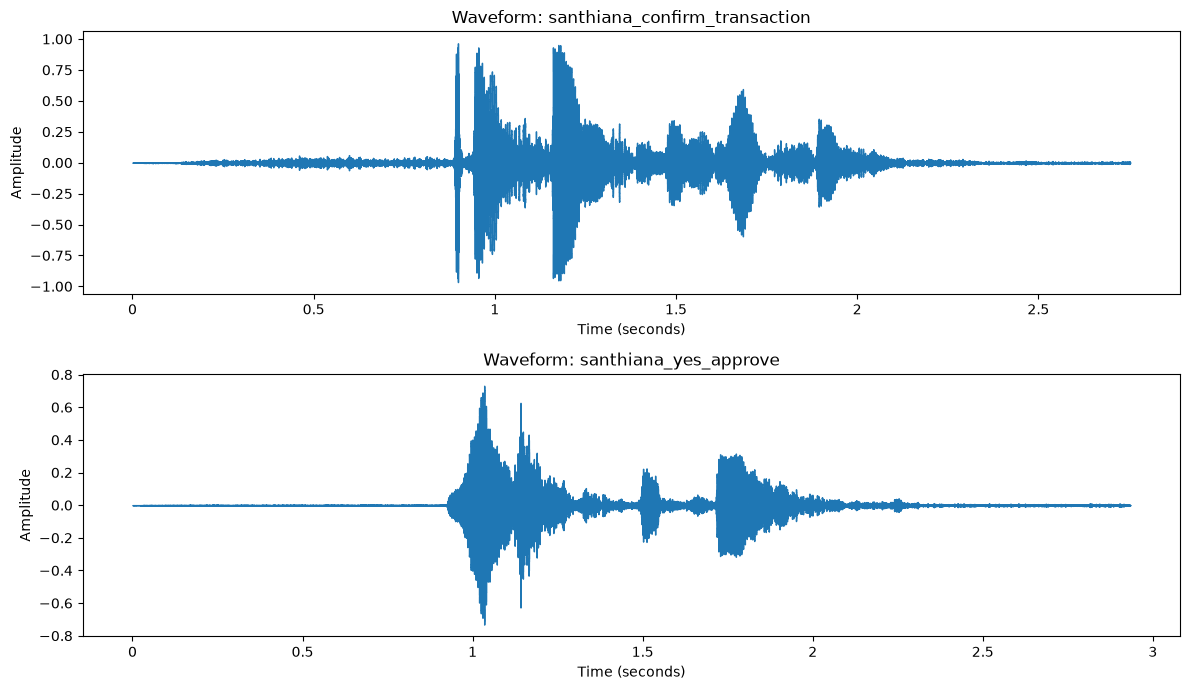

In [3]:
fig, axes = plt.subplots(len(audio_files), 1, figsize=(12, 7))

if len(audio_files) == 1:
    axes = [axes]

for ax, file in zip(axes, audio_files):
    audio, sr = librosa.load(file, sr=None)

    librosa.display.waveshow(audio, sr=sr, ax=ax)
    ax.set_title(f"Waveform: {file.stem}")
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Amplitude")

plt.tight_layout()
plt.show()

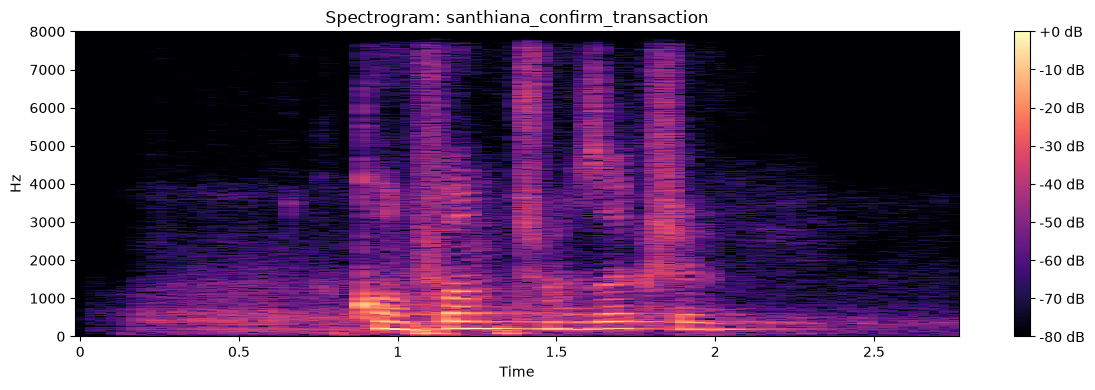

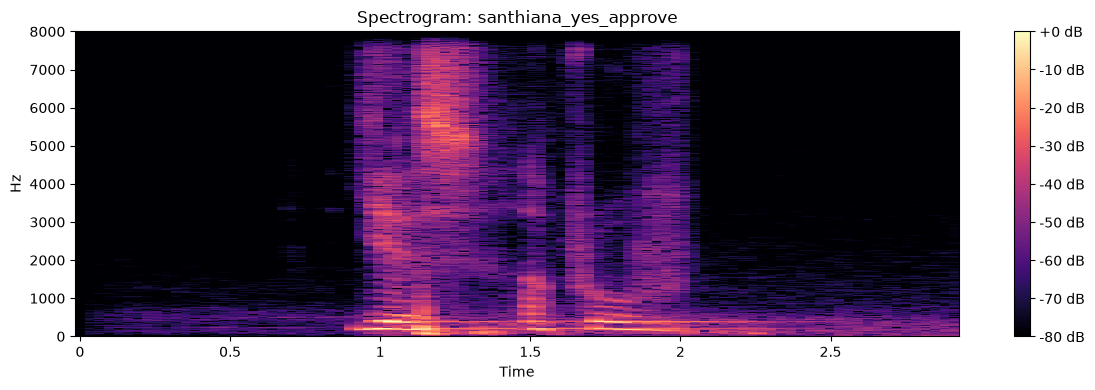

In [4]:
for file in audio_files:
    audio, sr = librosa.load(file, sr=None)

    D = librosa.amplitude_to_db(
        np.abs(librosa.stft(audio)),
        ref=np.max
    )

    plt.figure(figsize=(12, 4))

    librosa.display.specshow(
        D,
        sr=sr,
        x_axis="time",
        y_axis="hz"
    )

    plt.colorbar(format="%+2.0f dB")
    plt.title(f"Spectrogram: {file.stem}")
    plt.tight_layout()
    plt.show()

In [5]:
features_path = PROCESSED_DIR / "audio_features.csv"
features = pd.read_csv(features_path)

print("Feature dataset shape:", features.shape)
display(features.head())

print("\nFeature columns:")
print(features.columns.tolist())

print("\nMissing values:")
print(features.isnull().sum().sum())

print("\nAugmentation counts:")
print(features["variant"].value_counts())

Feature dataset shape: (12, 38)


,speaker,utterance,variant,filename,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,mfcc_2_std,mfcc_3_mean,mfcc_3_std,...,mfcc_13_mean,mfcc_13_std,rolloff_mean,rolloff_std,rms_mean,rms_std,centroid_mean,centroid_std,zcr_mean,zcr_std
0,santhiana,santhiana_confirm_transaction,clean,santhiana_confirm_transaction_clean.wav,-198.639954,89.870522,120.418350,43.656349,3.468596,22.680056,...,-6.769544,6.244468,2558.159668,1550.819824,0.104009,0.078382,1328.561646,716.005981,0.085142,0.054518
1,santhiana,santhiana_confirm_transaction,pitch_up,santhiana_confirm_transaction_pitch_up.wav,-157.541702,86.385078,111.022575,41.013985,4.782928,21.395683,...,-7.613295,5.719923,2930.266113,1537.697266,0.129411,0.098476,1442.688965,619.134338,0.084518,0.051418
2,santhiana,santhiana_confirm_transaction,pitch_down,santhiana_confirm_transaction_pitch_down.wav,-216.602066,83.584419,120.023613,39.567371,3.211543,18.722137,...,-10.662237,6.764782,2647.714111,1458.713257,0.079165,0.063405,1314.512207,586.967468,0.078197,0.045109
3,santhiana,santhiana_confirm_transaction,faster,santhiana_confirm_transaction_faster.wav,-206.295822,85.054131,115.108162,38.845417,5.545652,19.451153,...,-7.867810,5.094064,2777.573486,1428.080933,0.085771,0.065037,1344.226074,539.053101,0.075406,0.039426
4,santhiana,santhiana_confirm_transaction,slower,santhiana_confirm_transaction_slower.wav,-176.088409,83.437096,113.572266,42.624786,6.883564,19.978107,...,-8.725748,5.999929,2798.270020,1566.404907,0.113988,0.085999,1398.464233,642.379822,0.085449,0.041918



Feature columns:
['speaker', 'utterance', 'variant', 'filename', 'mfcc_1_mean', 'mfcc_1_std', 'mfcc_2_mean', 'mfcc_2_std', 'mfcc_3_mean', 'mfcc_3_std', 'mfcc_4_mean', 'mfcc_4_std', 'mfcc_5_mean', 'mfcc_5_std', 'mfcc_6_mean', 'mfcc_6_std', 'mfcc_7_mean', 'mfcc_7_std', 'mfcc_8_mean', 'mfcc_8_std', 'mfcc_9_mean', 'mfcc_9_std', 'mfcc_10_mean', 'mfcc_10_std', 'mfcc_11_mean', 'mfcc_11_std', 'mfcc_12_mean', 'mfcc_12_std', 'mfcc_13_mean', 'mfcc_13_std', 'rolloff_mean', 'rolloff_std', 'rms_mean', 'rms_std', 'centroid_mean', 'centroid_std', 'zcr_mean', 'zcr_std']

Missing values:
0

Augmentation counts:
variant
clean               2
pitch_up            2
pitch_down          2
faster              2
slower              2
background_noise    2
Name: count, dtype: int64


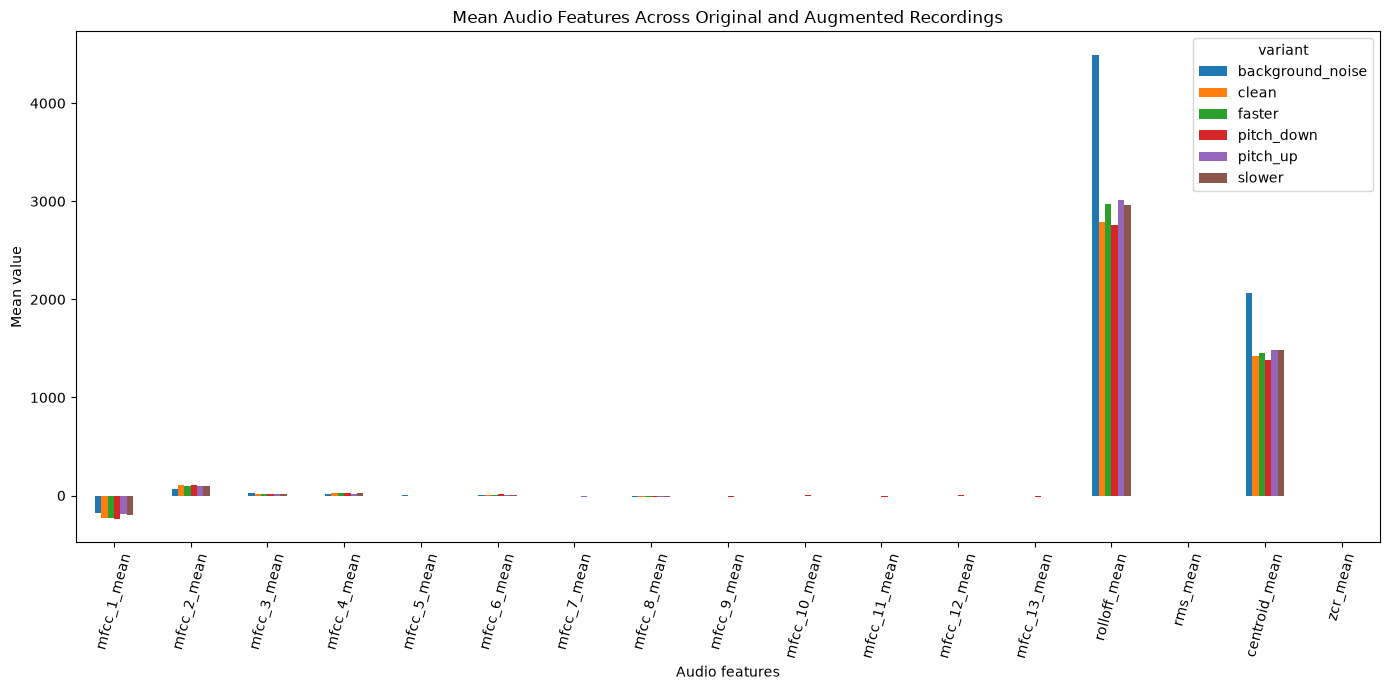

In [6]:
feature_columns = [
    col for col in features.columns
    if col.endswith("_mean")
]

features.groupby("variant")[feature_columns].mean().T.plot(
    figsize=(14, 7),
    kind="bar"
)

plt.title("Mean Audio Features Across Original and Augmented Recordings")
plt.xlabel("Audio features")
plt.ylabel("Mean value")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()